# Efficient LLM Customization Using Parameter-Efficient Fine-Tuning (LoRA)

Orion AI Labs builds AI writing assistants for enterprise clients. Their product uses a general-purpose LLM via API, but clients want responses tailored to specific styles and terminology. Prompt engineering alone has hit its limits — responses are inconsistent, and API costs keep climbing.

**The Solution:** "Project TuneCraft"
We need to fune tune the LLM to follow the instruction. So, we are building a Parameter-Efficient Fine-Tuning pipeline using LoRA (Low-Rank Adaptation). Instead of retraining billions of parameters, LoRA injects small, trainable adapter layers into the model. Your goal is to fine-tune TinyLlama-1.1B on dolly dataset and demonstrate measurable improvement in response quality.


In [1]:
# installing required libraries
!pip install -U transformers trl peft datasets accelerate torch torchvision torchao -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
# the default torchaudio installed is not compatible with torch cuda so uninstalling it
!pip uninstall -y torchaudio

Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130


In [3]:
# installing torchaudio again
!pip install torchaudio --index-url https://download.pytorch.org/whl/cu132 -q

In [4]:
# importing required classes
import torch
import gc
import os
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, PeftModel, get_peft_model
from trl import SFTConfig, SFTTrainer

W1102 13:00:34.947000 1582 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 13:00:35.037000 1582 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [5]:
# printing the Pytorch Version & GPU details
print(f"PyTorch Version:- {torch.__version__}")
print(f"CUDA available:- {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch Version:- 2.15.0+cu132
CUDA available:- True
GPU: Tesla T4


In [6]:
# function to free up cache in GPU
def clear_memory():
    """Free GPU memory between experiments."""
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        print(f"GPU allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
        print(f"GPU reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")

# function to print trainable v/s total parameters in the model
def print_trainable_params(model):
    """Display trainable vs total parameter counts."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable parameters: {trainable:>12,}  ({100 * trainable / total:.4f}%)")
    print(f"Total parameters:     {total:>12,}")

# function to generate the response using the model for the given prompt
def generate_response(model, tokenizer, prompt, max_new_tokens=256):
    """Generate a response from a model given a prompt string."""
    messages = [{"role": "user", "content": prompt}]
    input_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(input_text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            temperature=0.7,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.pad_token_id,
        )
    response = tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return response

## Stage 1: Baseline Model Evaluation

### Task 1.1: Define your hyperparameters (model name, dataset name, number of training samples, max sequence length)

In [7]:
# ============================================================
# Configuration
# ============================================================
MODEL_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"  # Base model
DATASET_NAME = "databricks/databricks-dolly-15k" # Instruction-tuning dataset
NUM_TRAIN_SAMPLES = 3000 # No. Of Samples to used for fine-tuning the Base Model
MAX_SEQ_LENGTH = 512 # Maximum sequence length

# LoRA hyperparameters
LORA_R = 8  # Rank
LORA_ALPHA = 16 # Scaling factor (2x rank)
LORA_DROPOUT = 0.05 # Regularization
LORA_TARGET_MODULES = ["q_proj", "v_proj"] #(attention only)

LEARNING_RATE = 2e-5
NUM_EPOCHS = 1
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4 # Effective batch size = 4 * 4 = 16
OUTPUT_DIR = "./sft-lora-tinyllama"

### Task 1.2: Load the base model and tokenizer with appropriate precision and device settings for a T4 GPU.


In [8]:
# load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Ensure pad token is set
if tokenizer.pad_token is None:
  tokenizer.pad_token = tokenizer.eos_token
  tokenizer.pad_token_id = tokenizer.eos_token_id

print(f"Vocabulary size: {len(tokenizer):,}")
print(f"Model max length: {tokenizer.model_max_length:,}")
print(f"Pad token: '{tokenizer.pad_token}' (id={tokenizer.pad_token_id})")

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

Vocabulary size: 32,000
Model max length: 2,048
Pad token: '</s>' (id=2)


In [9]:
#load the base model
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype = torch.float16,
    device_map = "auto",
    trust_remote_code = True
)

# print the no.of parameters & size
total_parameters = sum(p.numel() for p in model.parameters())
total_paramters_size = total_parameters/(1024 ** 3)
print(f'Total Parameters of the Model:- {MODEL_NAME} are {total_parameters/(1000**3):3f} Billion')
print(f'Total Parameters Size of the Model:- {MODEL_NAME} is {total_paramters_size:3f} GB')

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Total Parameters of the Model:- TinyLlama/TinyLlama-1.1B-Chat-v1.0 are 1.100048 Billion
Total Parameters Size of the Model:- TinyLlama/TinyLlama-1.1B-Chat-v1.0 is 1.024500 GB


### Task 1.3: Define a fixed list of test prompts and generate the model's baseline response to each one, storing them for later comparison.

In [10]:
# test prompts to evaluate instruction-following ability
test_prompts = [
    "Explain what a neural network is in 2-3 sentences.",
    "What are three tips for better sleep?"
]

# Store base responses for later comparison
base_responses = []

print("=="*70)
print("BASE MODEL RESPONSES")
print("=="*70)

for i, prompt in enumerate(test_prompts):
  print(f'\n{'-'*60}')
  print(f'Prompt {i+1}: {prompt}')
  print(f'\n{'-'*60}')
  response = generate_response(model, tokenizer, prompt, 500)
  print(f'Response: {response}')
  base_responses.append(response)

BASE MODEL RESPONSES

------------------------------------------------------------
Prompt 1: Explain what a neural network is in 2-3 sentences.

------------------------------------------------------------


[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=500) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Response: A neural network is a type of artificial neural system that mimics the way the human brain processes information. It consists of a collection of interconnected nodes (also called neurons), which are responsible for processing signals. Each node receives input signals from other nodes, and the output of a node depends on the inputs it receives. Neural networks can be trained to perform a specific task, such as recognizing images or analyzing financial data, by passing input signals through the network and observing the output signals. The process of training a neural network involves adjusting the weights and biases of the nodes to optimize the performance of the network.

------------------------------------------------------------
Prompt 2: What are three tips for better sleep?

------------------------------------------------------------
Response: 1. Establish a consistent sleep routine: Try to go to bed and wake up at the same time every day, even on weekends. This will he

## Stage 2: Dataset Engineering for Instruction Tuning

### Task 2.1: Load the Dolly-15K dataset and inspect its shape and columns.

In [11]:
#Load Dataset
raw_dataset = load_dataset(DATASET_NAME, split = "train")
print(f'Full dataset size {len(raw_dataset)}')
print(f'Columns: {raw_dataset.column_names}')
print(f"\nExample entry:")
print(raw_dataset[0])

README.md:   0%|          | 0.00/8.20k [00:00<?, ?B/s]

databricks-dolly-15k.jsonl: reconstructing file:   0%|          |  0.00B / 13.1MB            

databricks-dolly-15k.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15011 [00:00<?, ? examples/s]

Full dataset size 15011
Columns: ['instruction', 'context', 'response', 'category']

Example entry:
{'instruction': 'When did Virgin Australia start operating?', 'context': "Virgin Australia, the trading name of Virgin Australia Airlines Pty Ltd, is an Australian-based airline. It is the largest airline by fleet size to use the Virgin brand. It commenced services on 31 August 2000 as Virgin Blue, with two aircraft on a single route. It suddenly found itself as a major airline in Australia's domestic market after the collapse of Ansett Australia in September 2001. The airline has since grown to directly serve 32 cities in Australia, from hubs in Brisbane, Melbourne and Sydney.", 'response': 'Virgin Australia commenced services on 31 August 2000 as Virgin Blue, with two aircraft on a single route.', 'category': 'closed_qa'}


### Task 2.2: Write a formatting function that converts each example into a messages list with distinct user and assistant turns, merging the optional context into the user turn only when it's present.

In [12]:
# function to format instructions & responses from dolly format to conversational messages format
def format_dolly_to_chat(example):
  """
    Convert Dolly format (instruction/context/response/category) to conversational
    messages format for SFTTrainer.

    Dolly format:
        {"instruction": "...", "context": "...", "response": "...", "category": "..."}

    Target format (ChatML-style messages):
        {"messages": [
            {"role": "user", "content": "..."},
            {"role": "assistant", "content": "..."}
        ]}
  """

  if example.get("context") and example["context"].strip():
    user_content = f'{example["instruction"]}\n{example["context"]}'
  else:
    user_content = example["instruction"]
  return {
      "messages": [
          {"role": "user", "content": user_content},
          {"role": "assistant", "content": example["response"]}
      ]
  }

### Task 2.3: Select a training subset from the dataset and print a formatted example to verify the structure is correct.

In [13]:
# Apply formatting and take a subset for training
dataset = raw_dataset.shuffle(seed = 42).select(range(NUM_TRAIN_SAMPLES))
dataset = dataset.map(
    format_dolly_to_chat,
    remove_columns = raw_dataset.column_names,
    desc="Formatting to chat messages"
)

print(f"\nFormatted dataset size: {len(dataset):,}")
print(f"Columns: {dataset.column_names}")
print(f"\nExample formatted entry:")
sample = dataset[9]
print(sample)

# Verify the chat template renders correctly
print('\nRendered Chat Template:')
rendered = tokenizer.apply_chat_template(sample['messages'], tokenize = False)
print(rendered)

Formatting to chat messages:   0%|          | 0/3000 [00:00<?, ? examples/s]


Formatted dataset size: 3,000
Columns: ['messages']

Example formatted entry:
{'messages': [{'role': 'user', 'content': "As per the passage whose works did Narendranath study?\nIn 1871, at the age of eight, Narendranath enrolled at Ishwar Chandra Vidyasagar's Metropolitan Institution, where he went to school until his family moved to Raipur in 1877. In 1879, after his family's return to Calcutta, he was the only student to receive first-division marks in the Presidency College entrance examination.  He was an avid reader in a wide range of subjects, including philosophy, religion, history, social science, art and literature. He was also interested in Hindu scriptures, including the Vedas, the Upanishads, the Bhagavad Gita, the Ramayana, the Mahabharata and the Puranas. Narendra was trained in Indian classical music, and regularly participated in physical exercise, sports and organised activities. Narendra studied Western logic, Western philosophy and European history at the General As

## Stage 3: LoRA Configuration & Injection

### Task 3.1: Create a LoRA configuration that targets the attention projection layers, rather than all linear layers.

In [14]:
# Define LoRA configuration
peft_config = LoraConfig(
    r = LORA_R,                               # Rank of decomposition
    lora_alpha = LORA_ALPHA,                  # Scaling factor (alpha/r applied)
    lora_dropout = LORA_DROPOUT,              # Dropout for regularization
    bias = "none",                            # Don't train bias terms
    task_type = "CAUSAL_LM",                  # Decoder-only language model
    target_modules = LORA_TARGET_MODULES      # Layers for which weights to be fine-tuned
)

print("LoRA Configuration:")
print(f"  Rank (r):          {peft_config.r}")
print(f"  Alpha (α):         {peft_config.lora_alpha}")
print(f"  Effective scaling: {peft_config.lora_alpha / peft_config.r}")
print(f"  Dropout:           {peft_config.lora_dropout}")
print(f"  Target modules:    {peft_config.target_modules}")
print(f"  Task type:         {peft_config.task_type}")

LoRA Configuration:
  Rank (r):          8
  Alpha (α):         16
  Effective scaling: 2.0
  Dropout:           0.05
  Target modules:    {'v_proj', 'q_proj'}
  Task type:         CAUSAL_LM


### Task 3.2: Apply the LoRA configuration to the base model to produce a trainable PEFT model.

In [15]:
# Apply LoRA to the model and inspect
lora_model = get_peft_model(model, peft_config)

### Task 3.3: Inspect and print the trainable parameter count against the total parameter count to confirm it's under 1%.

In [16]:
print("\n" + "=" * 50)
print("PARAMETER COMPARISON")
print("=" * 50)
print_trainable_params(lora_model)

# Show the LoRA module structure for one layer
print("\n\nLoRA module example (layer 0, q_proj):")
print(lora_model.model.model.layers[0].self_attn.q_proj)


PARAMETER COMPARISON
Trainable parameters:    1,126,400  (0.1023%)
Total parameters:     1,101,174,784


LoRA module example (layer 0, q_proj):
lora.Linear(
  (base_layer): Linear(in_features=2048, out_features=2048, bias=False)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.05, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=2048, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=2048, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


## Stage 4: Supervised Fine-Tuning with SFTTrainer

### Task 4.1: Set up a training configuration for SFTTrainer, including batch size, gradient accumulation, mixed precision, and gradient checkpointing suited to a T4's memory limits.

In [17]:
# Training configuration
training_args = SFTConfig(
    output_dir = OUTPUT_DIR,
    num_train_epochs = NUM_EPOCHS,
    per_device_train_batch_size = BATCH_SIZE,
    gradient_accumulation_steps = GRAD_ACCUM_STEPS,
    learning_rate = LEARNING_RATE,
    weight_decay = 0.01,
    warmup_steps =  0.03,
    lr_scheduler_type = "cosine",

    gradient_checkpointing = True,
    gradient_checkpointing_kwargs = {"use_reentrant": False},
    optim = "adamw_torch",
    max_grad_norm = 1.0, #To prevent exploding gradients

    max_length = MAX_SEQ_LENGTH,
    packing = False,                         # Set True for efficiency with short examples
    dataset_kwargs = {"skip_prepare_dataset": False},

    fp16 =  True,
    #bf16 = torch.cuda.is_bf16_supported(), Commented as this is not compatible with this version of TESLA T4 GPU

    logging_steps = 10,
    logging_first_step = True,

    save_strategy = "steps",
    save_steps = 500,
    save_total_limit = 2,
    seed = 42
)

print("Training Configuration Summary:")
print(f"  Effective batch size:  {BATCH_SIZE * GRAD_ACCUM_STEPS}")
print(f"  Learning rate:         {LEARNING_RATE}")
print(f"  Epochs:                {NUM_EPOCHS}")
print(f"  Max sequence length:   {MAX_SEQ_LENGTH}")
print(f"  Precision:             fp16")
print(f"  Gradient checkpointing: {training_args.gradient_checkpointing}")
print(f"  Logging every:         {training_args.logging_steps} steps")

Training Configuration Summary:
  Effective batch size:  16
  Learning rate:         2e-05
  Epochs:                1
  Max sequence length:   512
  Precision:             fp16
  Gradient checkpointing: True
  Logging every:         10 steps


### Task 4.2: Instantiate SFTTrainer with your LoRA-wrapped model, prepared dataset, and training configuration.

In [18]:
# Create the trainer
trainer = SFTTrainer(
    model = lora_model,
    args = training_args,
    train_dataset = dataset,
    processing_class = tokenizer,
    #peft_config = peft_config #Comment this out for FULL Fine tuning
)

# Trainer Parameters
print("Model with LoRA adapters applied:")
print_trainable_params(trainer.model)

Tokenizing train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (4117 > 2048). Running this sequence through the model will result in indexing errors


Building labels for train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Model with LoRA adapters applied:
Trainable parameters:    1,126,400  (0.1023%)
Total parameters:     1,101,174,784


### Task 4.3: Run the training loop and monitor the training loss as it progresses.

In [19]:
# ════════════════════════════════════════════════
# TRAIN!
# ════════════════════════════════════════════════
print("\n Starting SFT with LORA...")
print(f"Training on {len(dataset):,} examples for {NUM_EPOCHS} epoch(s)")
print(f"Metrics logging every {training_args.logging_steps} steps\n")

train_result = trainer.train()
print("\n" + "=" * 50)
print("TRAINING COMPLETE")
print("=" * 50)
metrics = train_result.metrics
print(f"  Total training time: {metrics.get('train_runtime', 0):.1f} seconds")
print(f"  Samples/second:      {metrics.get('train_samples_per_second', 0):.2f}")
print(f"  Final loss:          {metrics.get('train_loss', 0):.4f}")
print(f"  Total steps:         {metrics.get('total_flos', 0):.2e} FLOPs")



 Starting SFT with LORA...
Training on 3,000 examples for 1 epoch(s)
Metrics logging every 10 steps



/usr/local/lib/python3.13/dist-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


Step,Training Loss
1,2.028632
10,2.074004
20,2.041896
30,2.090754
40,2.081039
50,2.127498
60,1.971531
70,1.931407
80,1.925916
90,1.912923



TRAINING COMPLETE
  Total training time: 464.9 seconds
  Samples/second:      6.45
  Final loss:          1.9297
  Total steps:         6.46e+15 FLOPs


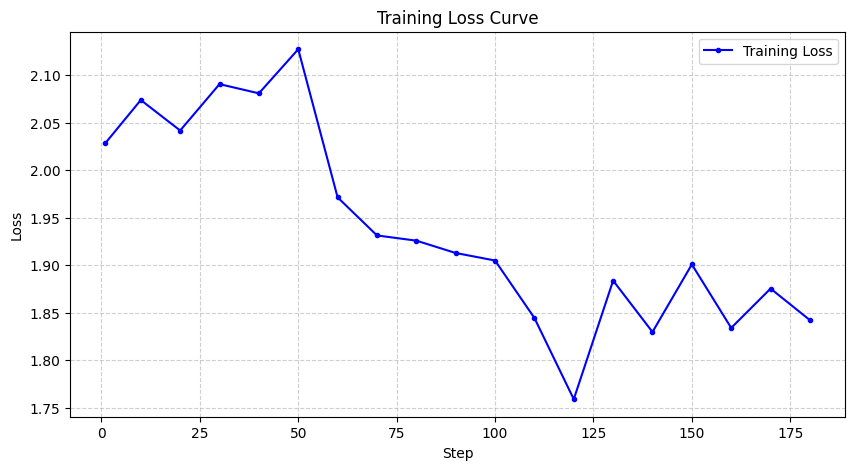

In [20]:
import matplotlib.pyplot as plt

# Extract training loss history from trainer log
train_log = trainer.state.log_history

# Filter out entries that contain training loss
steps = []
losses = []

for log in train_log:
    if "loss" in log:
        steps.append(log["step"])
        losses.append(log["loss"])

# Plot the training loss curve
plt.figure(figsize=(10, 5))
plt.plot(steps, losses, label="Training Loss", color="blue", marker="o", linestyle="-", markersize=3)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Stage 5: Adapter Persistence & Comparative Evaluation

### Task 5.1: Save the trained LoRA adapter and tokenizer to disk.

In [21]:
#Save the LoRA adapter
adapter_path = f"{OUTPUT_DIR}/final-adapter"
trainer.save_model(adapter_path)
tokenizer.save_pretrained(adapter_path)

('./sft-lora-tinyllama/final-adapter/tokenizer_config.json',
 './sft-lora-tinyllama/final-adapter/chat_template.jinja',
 './sft-lora-tinyllama/final-adapter/tokenizer.json')

### Task 5.2: Compute and print the on-disk size of the saved adapter.

In [22]:
# Check adapter size
adapter_size = sum(
    os.path.getsize(os.path.join(adapter_path, f))
    for f in os.listdir(adapter_path)
    if os.path.isfile(os.path.join(adapter_path, f))
)

print(f"\nAdapter saved to: {adapter_path}")
print(f"Adapter size: {adapter_size / 1024**2:.1f} MB")
print(f"(Compare to full model: ~{sum(p.numel() * 2 for p in model.parameters()) / 1024**3:.1f} GB)")


Adapter saved to: ./sft-lora-tinyllama/final-adapter
Adapter size: 7.8 MB
(Compare to full model: ~2.1 GB)


### Task 5.3: Generate responses from the fine-tuned model on the exact same test prompts used in Stage 1, and print a side-by-side comparison against the baseline responses.

In [23]:
# Create fine tuned model from the trainer.model(It already has the LoRA weights)
finetuned_model = trainer.model
finetuned_model.eval()

print("=" * 70)
print("FINE-TUNED MODEL RESPONSES (after SFT with LoRA)")
print("=" * 70)

finetuned_responses = []
for i, prompt in enumerate(test_prompts):
    print(f"\n{'─' * 60}")
    print(f"Prompt {i+1}: {prompt}")
    print(f"{'─' * 60}")
    response = generate_response(finetuned_model, tokenizer, prompt, max_new_tokens=200)
    finetuned_responses.append(response)
    print(f"Response: {response[:500]}")

[transformers] Both `max_new_tokens` (=200) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


FINE-TUNED MODEL RESPONSES (after SFT with LoRA)

────────────────────────────────────────────────────────────
Prompt 1: Explain what a neural network is in 2-3 sentences.
────────────────────────────────────────────────────────────


[transformers] Both `max_new_tokens` (=200) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Response: A neural network is a type of artificial intelligence that uses a collection of interconnected computational units (neurons) to simulate the functioning of the human brain. It processes data by identifying patterns and making predictions based on the data. Neural networks are trained using supervised or unsupervised learning techniques to learn from data and make accurate predictions.

────────────────────────────────────────────────────────────
Prompt 2: What are three tips for better sleep?
────────────────────────────────────────────────────────────
Response: 1. Create a consistent sleep schedule: Aim to sleep at the same time each night and wake up at the same time each morning.

2. Avoid caffeine and alcohol: These substances can interfere with your sleep.

3. Create a relaxing sleep environment: Turn off electronic devices, reduce noise, and create a warm and comfortable sleep environment.

4. Stick to a sleep routine: Establish a bedtime routine, such as taking a warm 

In [24]:
print("=" * 80)
print(" COMPARISON: BASE MODEL vs. FINE-TUNED MODEL (LoRA SFT)")
print("=" * 80)

for i, prompt in enumerate(test_prompts):
    print(f"\n{'━' * 80}")
    print(f"  PROMPT {i+1}: {prompt}")
    print(f"{'━' * 80}")

    print(f"\n  🔴 BASE MODEL:")
    print(f"  {base_responses[i]}")

    print(f"\n  🟢 FINE-TUNED (LoRA SFT):")
    print(f"  {finetuned_responses[i]}")
    print()

 COMPARISON: BASE MODEL vs. FINE-TUNED MODEL (LoRA SFT)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PROMPT 1: Explain what a neural network is in 2-3 sentences.
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  🔴 BASE MODEL:
  A neural network is a type of artificial neural system that mimics the way the human brain processes information. It consists of a collection of interconnected nodes (also called neurons), which are responsible for processing signals. Each node receives input signals from other nodes, and the output of a node depends on the inputs it receives. Neural networks can be trained to perform a specific task, such as recognizing images or analyzing financial data, by passing input signals through the network and observing the output signals. The process of training a neural network involves adjusting the weights and biases of the nodes to optimize the performance of the network.

  🟢 FINE-TUNED (Lo